In [1]:
import pandas as pd

In [2]:
edades = pd.Series(
    [25, 30.0, 40],
    name = "Edades",
    index = ["fila1", "fila2", "fila3"]
) # Datos 1D
edades

fila1    25.0
fila2    30.0
fila3    40.0
Name: Edades, dtype: float64

In [3]:
# DataFrame (2D)
clase_pypcd = {
    "Nombres": ["Alejandro", "Edgar", "Frida", "Joss", "Joca", "Isis"],
    "Edad": [20, 20, 22, 21, 21, 20],
    "Licenciatura de Origen": [
        "MAC", "Ingeniería en Computación",
        "MAC", "MAC", "MAC", "MAC"
    ],
    "Promedio": [8.7, 9.2, 9.1, 9.4, 8.9, 8.5],
    "Semestre Origen": ["Septimo", "Quinto", "Octavo", "Octavo", "Séptimo", "Séptimo"]
}

In [4]:
# Crear DataFrame
df_clase_pypcd = pd.DataFrame(clase_pypcd)

In [6]:
df_clase_pypcd

,Nombres,Edad,Licenciatura de Origen,Promedio,Semestre Origen
0,Alejandro,20,MAC,8.7,Septimo
1,Edgar,20,Ingeniería en Computación,9.2,Quinto
2,Frida,22,MAC,9.1,Octavo
3,Joss,21,MAC,9.4,Octavo
4,Joca,21,MAC,8.9,Séptimo
5,Isis,20,MAC,8.5,Séptimo


In [7]:
reemplazar_acentos = {
    "á": "a",
    "é": "e",
    "í": "i",
    "ó": "o",
    "ú": "u",
}
for old, new in reemplazar_acentos.items():
    df_clase_pypcd["Semestre Origen"] = df_clase_pypcd["Semestre Origen"].str.replace(old, new)

In [8]:
df_clase_pypcd.head(6) # Imprimer los primeros n elementos

,Nombres,Edad,Licenciatura de Origen,Promedio,Semestre Origen
0,Alejandro,20,MAC,8.7,Septimo
1,Edgar,20,Ingeniería en Computación,9.2,Quinto
2,Frida,22,MAC,9.1,Octavo
3,Joss,21,MAC,9.4,Octavo
4,Joca,21,MAC,8.9,Septimo
5,Isis,20,MAC,8.5,Septimo


In [9]:
# Acceder a una fila
df_clase_pypcd.iloc[5].loc["Nombres"]

'Isis'

In [10]:
df_clase_pypcd.iloc[[5]]

,Nombres,Edad,Licenciatura de Origen,Promedio,Semestre Origen
5,Isis,20,MAC,8.5,Septimo


In [11]:
# Acceder a columnas
df_clase_pypcd["Nombres"]

0    Alejandro
1        Edgar
2        Frida
3         Joss
4         Joca
5         Isis
Name: Nombres, dtype: str

In [12]:
df_clase_pypcd[["Nombres"]]

,Nombres
0,Alejandro
1,Edgar
2,Frida
3,Joss
4,Joca
5,Isis


In [13]:
df_clase_pypcd[["Nombres", "Licenciatura de Origen"]]

,Nombres,Licenciatura de Origen
0,Alejandro,MAC
1,Edgar,Ingeniería en Computación
2,Frida,MAC
3,Joss,MAC
4,Joca,MAC
5,Isis,MAC


In [14]:
df_clase_pypcd_tmp = (df_clase_pypcd
    [["Nombres", "Licenciatura de Origen"]]
    .iloc[2:5]
)

In [15]:
df_clase_pypcd_tmp

,Nombres,Licenciatura de Origen
2,Frida,MAC
3,Joss,MAC
4,Joca,MAC


In [16]:
# Crear columna
df_clase_pypcd["Promedio100"] = df_clase_pypcd["Promedio"] * 10

In [17]:
# Eliminar columna
del df_clase_pypcd["Promedio"]

In [18]:
# Máscara booleana
df_clase_pypcd["Edad"] >= df_clase_pypcd["Edad"].mean()

0    False
1    False
2     True
3     True
4     True
5    False
Name: Edad, dtype: bool

In [19]:
# Filtrar información
df_clase_pypcd[
    df_clase_pypcd["Edad"] >= df_clase_pypcd["Edad"].mean()
]

,Nombres,Edad,Licenciatura de Origen,Semestre Origen,Promedio100
2,Frida,22,MAC,Octavo,91.0
3,Joss,21,MAC,Octavo,94.0
4,Joca,21,MAC,Septimo,89.0


In [20]:
df_clase_pypcd

,Nombres,Edad,Licenciatura de Origen,Semestre Origen,Promedio100
0,Alejandro,20,MAC,Septimo,87.0
1,Edgar,20,Ingeniería en Computación,Quinto,92.0
2,Frida,22,MAC,Octavo,91.0
3,Joss,21,MAC,Octavo,94.0
4,Joca,21,MAC,Septimo,89.0
5,Isis,20,MAC,Septimo,85.0


In [21]:
df_clase_pypcd.mean(axis = 1, numeric_only = True)

0    53.5
1    56.0
2    56.5
3    57.5
4    55.0
5    52.5
dtype: float64

In [22]:
def upperFAlphabet(row):
    return row.lower() > "f"

In [23]:
df_clase_pypcd["upperFAlphabet"] = df_clase_pypcd["Nombres"].apply(upperFAlphabet)

In [24]:
print(df_clase_pypcd.to_latex())

\begin{tabular}{llrllrr}
\toprule
 & Nombres & Edad & Licenciatura de Origen & Semestre Origen & Promedio100 & upperFAlphabet \\
\midrule
0 & Alejandro & 20 & MAC & Septimo & 87.000000 & False \\
1 & Edgar & 20 & Ingeniería en Computación & Quinto & 92.000000 & False \\
2 & Frida & 22 & MAC & Octavo & 91.000000 & True \\
3 & Joss & 21 & MAC & Octavo & 94.000000 & True \\
4 & Joca & 21 & MAC & Septimo & 89.000000 & True \\
5 & Isis & 20 & MAC & Septimo & 85.000000 & True \\
\bottomrule
\end{tabular}



<Axes: xlabel='Licenciatura de Origen'>

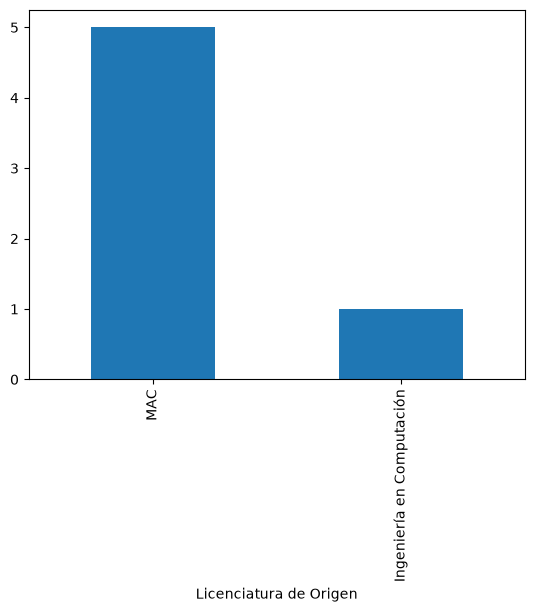

In [25]:
df_clase_pypcd["Licenciatura de Origen"].value_counts().plot.bar()

In [26]:
#Serie multiindex
df_clase_pypcd[["Licenciatura de Origen", "Semestre Origen"]].value_counts()

Licenciatura de Origen     Semestre Origen
MAC                        Septimo            3
                           Octavo             2
Ingeniería en Computación  Quinto             1
Name: count, dtype: int64

In [27]:
df_grafica = df_clase_pypcd[["Licenciatura de Origen", "Semestre Origen"]].value_counts().reset_index()

In [28]:
df_grafica

,Licenciatura de Origen,Semestre Origen,count
0,MAC,Septimo,3
1,MAC,Octavo,2
2,Ingeniería en Computación,Quinto,1


array([<Axes: title={'center': 'count'}, xlabel='Categorias', ylabel='Conteo'>],
      dtype=object)

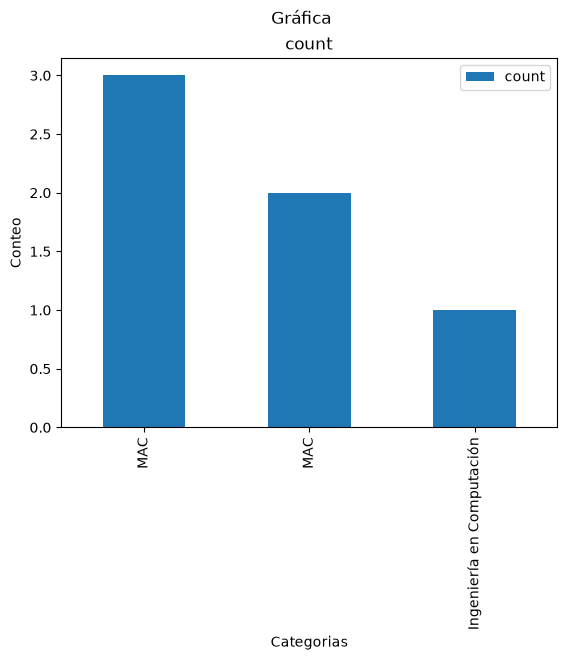

In [29]:
df_grafica.plot.bar(
    x="Licenciatura de Origen",
    y="count",
    subplots=True,
    xlabel="Categorias",
    ylabel="Conteo",
    title="Gráfica",
)

In [33]:
df_pivot

Semestre Origen,Octavo,Quinto,Septimo
Licenciatura de Origen,,,
Ingeniería en Computación,NaN,1.0,NaN
MAC,2.0,NaN,3.0


<Axes: xlabel='Licenciatura de Origen'>

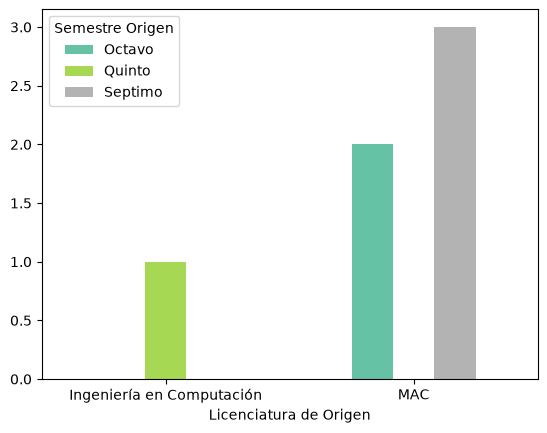

In [31]:
df_pivot = df_grafica.pivot(index='Licenciatura de Origen', columns='Semestre Origen', values='count')
df_pivot.plot.bar(rot=0, cmap='Set2')